In [1]:
#Below is the code used to generate the plots of the various Poisson Laguerre Flows at different values of alpha. Updated 23-10-2026.

Automated checks:


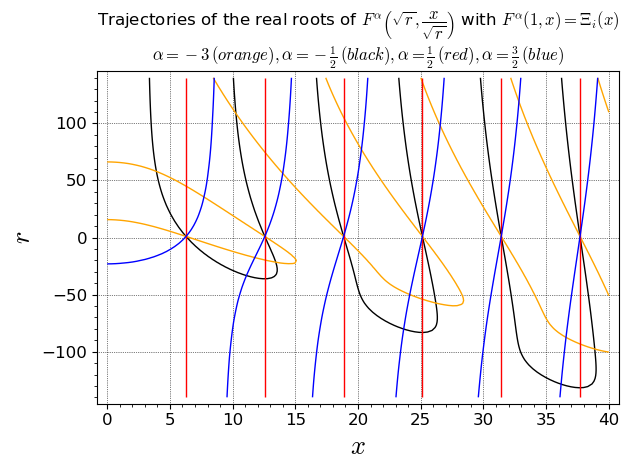

In [25]:
##Laguerre Flow direct evaluation for F = Xi_i

#Generate a plot of all ordinates of the zeros < 60 to overlay the flow graphs
var('y','t')
ord = []
for y in range(6):
    ord.append([2*pi()*(y+1),1])
    ord.append([-2*pi()*(y+1),1])
z1=list_plot(ord, size=15, marker="o", color = "black")

CCF=ComplexBallField(200)
RDF=RealBallField(1024)

#set alpha once here:
global alpha
alpha = CCF("-0.5")

def Xin(t):
    Xin=2 * CCF(t / 2).sin() / CCF(t)
    return Xin

#Laguerre flow closed form for F=Xi_i Humbert series expressed as finite series of 1F1s
CCF=ComplexBallField(200)
def LaguerreFlow(t, r):
    tr = CCF(t)
    rr = CCF(r).sqrt()
    tr = tr / rr
    sumn=(CCF(0));
    for n in range(200):
        summandn =  CCF(-1).pow(n) / CCF(2*n+2).gamma() * CCF((CCF(rr).pow(2)-1)/16).hypergeometric([CCF(alpha + n + 1)],[CCF("1.5")+n]) * CCF(tr * rr / 2).pow(2*n)
        sumn = sumn + summandn
    return sumn.mid()

#compute d/dr zk Newton approximation
def dzdrzk(k):
    tr = RDF("0.00000001");x0 = 2*k*RDF.pi();
    while(y):
        hd = (LaguerreFlow(x0 + tr*100,1+tr) - LaguerreFlow(x0,1+tr))/(tr*100)
        h = LaguerreFlow(x0,1+tr)/hd ;x1 = x0 - h;ab = h.abs();x0 = x1
        if ab < tr:
            break
    dzdr3 = -1*(x1 - 2*k*RDF.pi())/(tr) 
    return dzdr3

#compute d/dr zk via formula
def verifyPDE(k):
    return 1/(2*k*pi())-(CCF(alpha)+CCF("0.5"))/(2*k*pi())+2*k*pi()

print("Automated checks:")
#print("Ensure 20 digits accuracy at t = 60  : %3.20f (should show 20 zeros)." % real_part(LaguerreFlow(60,I)-Xin(60)))

am12i=implicit_plot(lambda t,r:(LaguerreFlow(t,r)),(t,0,40),(r,-140,140),color='black',fontsize=12,linestyle ="-",linewidth=1,gridlines=True,plot_points=120)

global alpha
alpha = CCF("-3")
am1d5i=implicit_plot(lambda t,r:(LaguerreFlow(t,r)),(t,0,40),(r,-140,140),color='orange',fontsize=12,linestyle ="-",linewidth=1, gridlines=True,plot_points=120)

global alpha
alpha = CCF("0.5")
a05i=implicit_plot(lambda t,r:(LaguerreFlow(t,r)),(t,0,40),(r,-140,140),color='red',fontsize=12,linestyle ="-",linewidth=1, gridlines=True,plot_points=120)

global alpha
alpha = CCF("1.5")
a15i=implicit_plot(lambda t,r:(LaguerreFlow(t,r)),(t,0,40),(r,-140,140),color='blue',fontsize=12,linestyle ="-",linewidth=1,axes_labels=['$x$','$r$'],title='Trajectories of the real roots of ' + r'$F^{\alpha}\left(\sqrt{r},\dfrac{x}{\sqrt{r}}\right)$ with $F^\alpha(1,x) = \Xi_i(x)$'+'\n'+ r'$\alpha = -3\, ( orange), \alpha = -\frac{1}{2}\, ( black), \alpha = \frac{1}{2}\, ( red), \alpha = \frac{3}{2}\, ( blue)$',gridlines=True,plot_points=120)

show(am12i + am1d5i + a05i + a15i,aspect_ratio='automatic')

Automated checks:


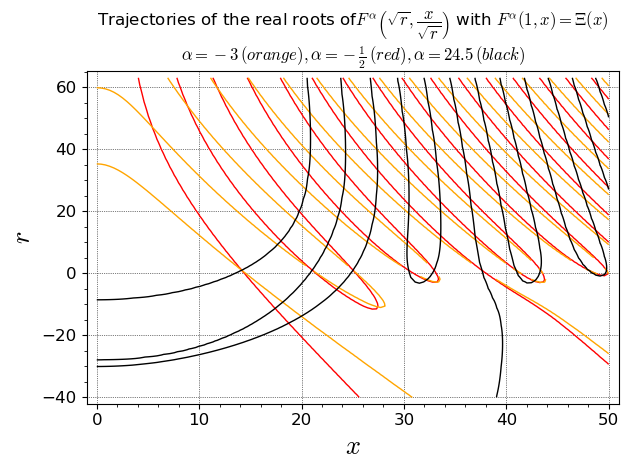

In [24]:
##Laguerre Flow direct evaluation for F = Xi_i

#Generate a plot of all ordinates of the zeros < 60 to overlay the flow graphs
var('y','t')
ord = []
for y in range(6):
    ord.append([2*pi()*(y+1),1])
    ord.append([-2*pi()*(y+1),1])
z1=list_plot(ord, size=15, marker="o", color = "black")

CCF=ComplexBallField(1024)
RDF=RealBallField(1024)

#set alpha once here:
global alpha
alpha = CCF("0.5")

global m1; m1 = []; CoeffSum = RDF(0); 
k = 0
with open("DerivsE0.txt", "r") as f:
    for row in f:
        CoeffSum = CoeffSum + RDF(row) * CCF(k+1).gamma() / CCF(2*k+1).gamma()
        m1.append([RDF(row)])
        k = k + 1
        
def Xi(t):
    f=CCF("-0.5",0)+I*CCF(t)
    xi=f/2*(f-1)*CCF(pi).pow(-f/2)*(f/2).gamma()*f.zeta()
    return xi

def LagPol(t,n):
    return CCF(t).laguerre_L(n, alpha)

def LaguerreFlow(tt,rr):
    r = CCF(rr); t = CCF(tt);
    r = CCF(r).sqrt()
    t = t / r;
    sum=CCF(0)
    for n in range(660):
        sum=sum+CCF(str(m1[2*n])) * CCF(n+1).gamma() / CCF(2*n+1).gamma() * CCF(1-r*r).pow(n) * LagPol(t*t*r*r/(r*r-1),n)
    return sum;

def LaguerreFlowDer(t,r):
    tr = CCF(t)
    rr = CCF(r)
    f1 = LaguerreFlow(tr + CCF("0.0000000000000001"), rr)
    f2 = LaguerreFlow(tr, rr)
    return ((f1-f2) / CCF("0.0000000000000001")).mid()

#compute d/dr zk Newton approximation
def dzdrzk(k):
    tr = RDF("0.00000001");x0 = 2*k*RDF.pi();
    while(y):
        hd = (LaguerreFlow(x0 + tr*100,1+tr) - LaguerreFlow(x0,1+tr))/(tr*100)
        h = LaguerreFlow(x0,1+tr)/hd ;x1 = x0 - h;ab = h.abs();x0 = x1
        if ab < tr:
            break
    dzdr3 = -1*(x1 - 2*k*RDF.pi())/(tr) 
    return dzdr3

#compute d/dr zk via formula
def verifyPDE(k):
    return 1/(2*k*pi())-(CCF(alpha)+CCF("0.5"))/(2*k*pi())+2*k*pi()

print("Automated checks:")
#print("Ensure 20 digits accuracy at t = 60  : %3.20f (should show 20 zeros)." % real_part(LaguerreFlow(60,I)-Xin(60)))

xt = [10 * k for k in range(0,7)]
xt_lbl = ['$0$', '$10$', '$20$', '$30$', '$40$', '$50$', '$60$']
yt = [2 * k for k in range(-7, 1)]
yt_lbl = ['$-14i$', '$-12i$', '$-10i$', '$-8i$', '$-6i$', '$-4i$', '$-2i$', '$0i$']

a12=implicit_plot(lambda t,r:real_part(LaguerreFlow(t,r)),(t,0,50),(r,-40,63),color='red',fontsize=12,linestyle ="-",linewidth=1,gridlines=True,plot_points=120)

alpha = CCF("-3")
a12d=implicit_plot(lambda t,r:real_part(LaguerreFlow(t,r)),(t,0,50),(r,-40,63),color='orange',fontsize=12,linestyle ="-",linewidth=1,gridlines=True,plot_points=120)

alpha = CCF("24.5")
a15=implicit_plot(lambda t,r:real_part(LaguerreFlow(t,r)),(t,0,50),(r,-40,63),color='black',fontsize=12,axes_labels=['$x$','$r$'],linestyle ="-",linewidth=1,title='Trajectories of the real roots of' +r'$F^{\alpha}\left(\sqrt{r},\dfrac{x}{\sqrt{r}}\right)$ with $F^\alpha(1,x) = \Xi(x)$'+'\n'+ r'$\alpha = -3\, ( orange), \alpha = -\frac{1}{2}\, ( red), \alpha = 24.5\, ( black)$',gridlines=True,plot_points=120)

show(a12 + a12d + a15,aspect_ratio='automatic')

In [26]:
#CASE 0 a=1 b=2
import numpy as np
import plotly.graph_objects as go

# --- Changeable Parameters ---
alpha = 2/3
rho_start = -1
rho_end = 3
num_points = 2000
# -----------------------------

# Generate values for rho
rho_values = np.linspace(rho_start, rho_end, num_points)

# Lists to store the coordinates of the roots
real_rho, real_re, real_im = [], [], []
comp_rho, comp_re, comp_im = [], [], []

for rho in rho_values:
    # Apply the substitution r = exp(-rho)
    r = np.exp(-rho)
    #r= rho
    
    # Coefficients for a4*t^4 + a3*t^3 + a2*t^2 + a1*t + a0 = 0
    # Derived from image_951ecd.png
    #a4 = r**4
    #a3 = 0
    #a2 = -2 * r**2 * (r**2 * (alpha + 2) - (alpha + 3))
    #a1 = 0
    #a0 = r**4 * (alpha + 1) * (alpha + 2) - 2 * r**2 * (alpha + 1) * (alpha + 3) + alpha**2 + 5 * alpha + 9
    a4 = r**4
    a3 = 0
    a2 = (2*alpha - 1)*r**2 - 2*(alpha + 2)*r**4
    a1 = 0
    a0 = (alpha + 1)*(alpha + 2)*r**4 - (2*alpha**2 + alpha - 1)*r**2 + (alpha - 1)**2

          
    # Calculate the roots using numpy
    coeffs = [a4, a3, a2, a1, a0]
    roots = np.roots(coeffs)
    
    # Separate into real and complex roots
    for root in roots:
        # Check if the imaginary part is effectively zero
        if np.isclose(root.imag, 0, atol=1e-7):
            real_rho.append(rho)
            real_re.append(root.real)
            real_im.append(0.0) # Snap to exactly 0 for visualization
        else:
            comp_rho.append(rho)
            comp_re.append(root.real)
            comp_im.append(root.imag)

# --- Create the 3D Plot ---
fig = go.Figure()

# Add Real Zeros (Green)
fig.add_trace(go.Scatter3d(
    x=real_rho, 
    y=real_re, 
    z=real_im,
    mode='markers',
    marker=dict(size=1, color='green', opacity=0.8),
    name='Real Zeros'
))

# Add Complex Zeros (Red)
fig.add_trace(go.Scatter3d(
    x=comp_rho, 
    y=comp_re, 
    z=comp_im,
    mode='markers',
    marker=dict(size=1, color='red', opacity=0.8),
    name='Complex Zeros'
))

# Add Blue dotted line across Im(t) = 0 (Runs along the rho axis at Re(t)=0)
fig.add_trace(go.Scatter3d(
    x=[rho_start, rho_end], 
    y=[0, 0], 
    z=[0, 0],
    mode='lines',
    line=dict(color='blue', width=4, dash='dot'),
    name='Im(t) = 0'
))

# Add Brown dotted line where Re(t) = 0 (Runs along the Im(t) axis at rho = 0)
min_im = min(comp_im) if comp_im else -2
max_im = max(comp_im) if comp_im else 2

fig.add_trace(go.Scatter3d(
    x=[0, 0], 
    y=[0, 0], 
    z=[min_im, max_im],
    mode='lines',
    line=dict(color='blue', width=4, dash='dot'),
    name='Re(t) = 0'
))

# Add Blue dotted line where rho = 0 and Im(t) = 0 (Runs along the Re(t) axis)
all_re = real_re + comp_re
min_re = min(all_re) if all_re else -2
max_re = max(all_re) if all_re else 2

fig.add_trace(go.Scatter3d(
    x=[0, 0], 
    y=[min_re, max_re], 
    z=[0, 0],
    mode='lines',
    line=dict(color='blue', width=4, dash='dot'),
    name='ρ = 0, Im(t) = 0'
))

# Configure the layout
fig.update_layout(
    title= f'3D Zeros of F^α(s, z) for α = {alpha}',
    scene=dict(
        xaxis_title='s',
        yaxis_title='Re(z)',
        zaxis_title='Im(z)'
    ),
    margin=dict(l=0, r=0, b=0, t=40),
    legend=dict(x=0.8, y=0.9)
)

# Open the interactive plot in your default web browser
fig.show()